# 02 - EDA: Atendimento e Cliente

**Responsavel:** Felipe
**Base:** `data/processed/desafio_nps_fase_1_clean.csv` (base tratada pelo notebook `01-cleansing.ipynb`)

Esta analise responde a parte da Etapa 3 do desafio ligada a **atendimento e perfil do cliente**:

| Tema | Pergunta |
| --- | --- |
| Reclamacoes | Clientes com mais reclamacoes tem notas menores? |
| Contatos com atendimento | Precisar contatar mais vezes esta associado a menor satisfacao? |
| Tempo de resolucao | Demorar para resolver piora a avaliacao? |
| Atraso x reclamacoes | A combinacao dos dois piora o resultado? |
| Perfil do cliente | Existe diferenca por regiao, idade ou valor do pedido? |
| Recompra | Clientes mais satisfeitos voltam a comprar? |

A parte de logistica (atraso, prazo, frete, tentativas) e analisada em outro notebook.

## 1. Setup e carga da base tratada

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
PALETA = '#2E6F9E'

# Base tratada gerada pelo notebook 01-cleansing.ipynb
CAMINHO_BASE = '../data/processed/desafio_nps_fase_1_clean.csv'
df = pd.read_csv(CAMINHO_BASE)

print(f'Base tratada: {df.shape[0]} linhas x {df.shape[1]} colunas')
df.head()

Base tratada: 2465 linhas x 19 colunas


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 2. Classificacao do NPS

O NPS padrao usa notas inteiras. Nesta base as notas tem casa decimal (ex.: 6,9), entao a regra adotada e:

- **Detrator:** nota menor que 7
- **Neutro:** nota de 7 a 8,99
- **Promotor:** nota de 9 a 10

O **NPS** e a diferenca entre o percentual de promotores e o de detratores, numa escala de -100 a +100.

In [2]:
def classificar_nps(nota):
    """Classifica a nota de NPS em Detrator, Neutro ou Promotor."""
    if nota < 7:
        return 'Detrator'
    elif nota < 9:
        return 'Neutro'
    return 'Promotor'

df['categoria_nps'] = df['nps_score'].apply(classificar_nps)

# Distribuicao e NPS geral
distribuicao = df['categoria_nps'].value_counts(normalize=True).reindex(['Promotor', 'Neutro', 'Detrator'])
nps_geral = (distribuicao['Promotor'] - distribuicao['Detrator']) * 100

print((distribuicao * 100).round(1).to_string())
print(f'\nNPS geral: {nps_geral:.0f}')
print(f'Nota media: {df["nps_score"].mean():.2f} | Nota mediana: {df["nps_score"].median():.2f}')

categoria_nps
Promotor     4.4
Neutro      11.1
Detrator    84.5

NPS geral: -80
Nota media: 4.38 | Nota mediana: 4.40


## 3. Checagem dos campos desta analise

Antes de analisar, confiro valores ausentes, faixas e inconsistencias nas colunas de atendimento e de perfil.

In [3]:
colunas_atendimento = ['customer_service_contacts', 'complaints_count', 'resolution_time_days']
colunas_perfil = ['customer_region', 'customer_age', 'customer_tenure_months', 'order_value']

print('Valores ausentes:')
print(df[colunas_atendimento + colunas_perfil].isna().sum().to_string())

print('\nEstatisticas das colunas de atendimento:')
display(df[colunas_atendimento].describe().T.round(2))

# Inconsistencia conhecida da base: reclamacao registrada sem nenhum contato com o atendimento
sem_contato_com_reclamacao = ((df['customer_service_contacts'] == 0) & (df['complaints_count'] > 0)).sum()
# e tempo de resolucao registrado sem nenhum problema aberto
resolucao_sem_problema = ((df['complaints_count'] == 0) & (df['resolution_time_days'] > 0)).sum()

print(f'\nReclamacao registrada sem nenhum contato: {sem_contato_com_reclamacao} pedidos')
print(f'Tempo de resolucao > 0 sem nenhuma reclamacao: {resolucao_sem_problema} pedidos')
print('Esses casos merecem validacao com a area de negocio (a reclamacao pode ter sido feita por outro canal) e entram nas limitacoes.')

Valores ausentes:
customer_service_contacts    0
complaints_count             0
resolution_time_days         0
customer_region              0
customer_age                 0
customer_tenure_months       0
order_value                  0

Estatisticas das colunas de atendimento:


,count,mean,std,min,25%,50%,75%,max
customer_service_contacts,2465.0,1.52,1.23,0.0,1.0,1.0,2.0,7.0
complaints_count,2465.0,4.15,1.78,0.0,3.0,4.0,5.0,11.0
resolution_time_days,2465.0,5.49,3.46,0.0,2.0,6.0,8.0,11.0



Reclamacao registrada sem nenhum contato: 522 pedidos
Tempo de resolucao > 0 sem nenhuma reclamacao: 22 pedidos
Esses casos merecem validacao com a area de negocio (a reclamacao pode ter sido feita por outro canal) e entram nas limitacoes.


## 4. Funcao de apoio

Para nao repetir codigo, esta funcao resume a nota media e o percentual de detratores por grupo.

In [4]:
def resumo_por_grupo(dados, coluna):
    """Retorna nota media, percentual de detratores e de promotores por valor da coluna."""
    resumo = dados.groupby(coluna).agg(
        pedidos=('nps_score', 'size'),
        nota_media=('nps_score', 'mean'),
        pct_detratores=('categoria_nps', lambda s: (s == 'Detrator').mean() * 100),
        pct_promotores=('categoria_nps', lambda s: (s == 'Promotor').mean() * 100),
    ).round(2)
    resumo['nps_grupo'] = (resumo['pct_promotores'] - resumo['pct_detratores']).round(0)
    return resumo


def grafico_nota_e_detratores(resumo, titulo, rotulo_x):
    """Barras = nota media; linha = percentual de detratores (eixo da direita)."""
    fig, eixo = plt.subplots(figsize=(9, 4.5))
    eixo.bar(resumo.index.astype(str), resumo['nota_media'], color=PALETA)
    eixo.set_ylabel('Nota media (0-10)')
    eixo.set_xlabel(rotulo_x)
    eixo.set_ylim(0, 10)

    eixo2 = eixo.twinx()
    eixo2.plot(resumo.index.astype(str), resumo['pct_detratores'], color='#C0392B', marker='o')
    eixo2.set_ylabel('% de detratores', color='#C0392B')
    eixo2.set_ylim(0, 105)
    eixo2.grid(False)

    eixo.set_title(titulo)
    plt.tight_layout()
    plt.show()

## 5. Reclamacoes

**Pergunta:** clientes com mais reclamacoes apresentam notas menores ou maior proporcao de detratores?

,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
complaints_count,,,,,
0,23,8.52,17.39,39.13,22.0
1,118,7.76,30.51,21.19,-9.0
2,272,6.03,66.18,11.40,-55.0
3,500,4.92,81.80,4.40,-77.0
4,595,4.23,89.75,2.86,-87.0
5,436,3.66,94.50,0.69,-94.0
6,264,3.07,97.35,0.00,-97.0
7,168,2.82,97.02,0.00,-97.0
8,61,2.05,100.00,0.00,-100.0


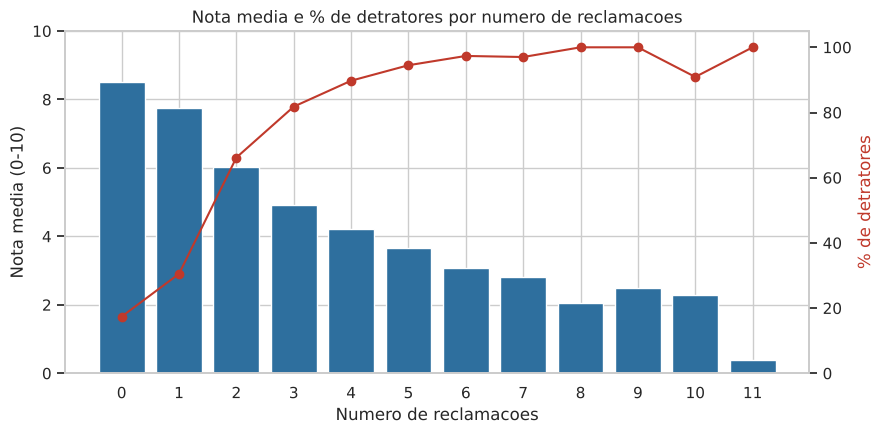

Correlacao entre reclamacoes e nota: -0.49
Correlacao vai de -1 a +1. Negativa significa que, quando um sobe, o outro desce.


In [5]:
resumo_reclamacoes = resumo_por_grupo(df, 'complaints_count')
display(resumo_reclamacoes)

grafico_nota_e_detratores(resumo_reclamacoes, 'Nota media e % de detratores por numero de reclamacoes', 'Numero de reclamacoes')

correlacao = df['complaints_count'].corr(df['nps_score'])
print(f'Correlacao entre reclamacoes e nota: {correlacao:.2f}')
print('Correlacao vai de -1 a +1. Negativa significa que, quando um sobe, o outro desce.')

Conclusao:

Quanto maior o número de reclamações, menor a nota média e maior a proporção de detratores. A nota cai de 8,5, sem reclamações, para cerca de 2 com 8 ou mais, enquanto os detratores aumentam de 17% para quase 100%.

A principal mudança ocorre entre 1 e 3 reclamações, quando os detratores passam de 31% para 82%.

Como apenas 23 pedidos não tiveram reclamações, a comparação mais confiável está entre os grupos de 1 a 3 reclamações, que possuem entre 118 e 500 pedidos.

## 6. Contatos com o atendimento

**Pergunta:** precisar entrar em contato mais vezes esta associado a menor satisfacao?

,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
customer_service_contacts,,,,,
0,545,5.53,71.19,10.28,-61.0
1,803,4.65,84.18,4.36,-80.0
2,638,4.12,88.56,2.19,-86.0
3,305,3.23,93.11,0.66,-92.0
4,131,2.65,97.71,0.76,-97.0
5,33,2.27,96.97,0.00,-97.0
6,7,0.74,100.00,0.00,-100.0
7,3,1.20,100.00,0.00,-100.0


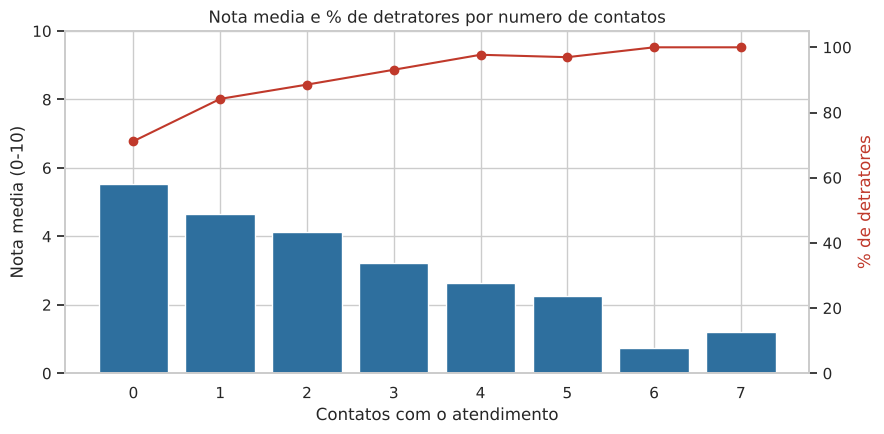

Correlacao entre contatos e nota: -0.35


In [6]:
resumo_contatos = resumo_por_grupo(df, 'customer_service_contacts')
display(resumo_contatos)

grafico_nota_e_detratores(resumo_contatos, 'Nota media e % de detratores por numero de contatos', 'Contatos com o atendimento')

print(f"Correlacao entre contatos e nota: {df['customer_service_contacts'].corr(df['nps_score']):.2f}")

Conclusao:

Quanto maior o número de contatos com o atendimento, menor a nota média. A avaliação cai de 5,5 entre clientes que não precisaram de atendimento para 4,7 com um contato, 3,2 com três e 2,6 com quatro contatos.

Os clientes mais satisfeitos são os que não precisaram acionar o atendimento, indicando que o contato tende a ocorrer quando já existe algum problema na experiência.

A partir de 5 contatos, o número de pedidos é muito baixo (33, 7 e 3), tornando essas médias instáveis e pouco adequadas para conclusões mais fortes.

## 7. Tempo de resolucao

**Pergunta:** quanto mais tempo o problema demora para ser resolvido, pior e a avaliacao?

,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
resolution_time_days,,,,,
0,205,5.30,75.61,9.27,-66.0
1,191,5.02,75.92,7.85,-68.0
2,224,4.81,82.14,5.36,-77.0
3,233,4.63,78.11,6.87,-71.0
4,204,4.43,85.29,4.90,-80.0
5,173,4.41,86.13,2.89,-83.0
6,194,4.33,85.57,4.12,-81.0
7,210,4.25,86.19,2.38,-84.0
8,226,3.96,88.94,2.65,-86.0


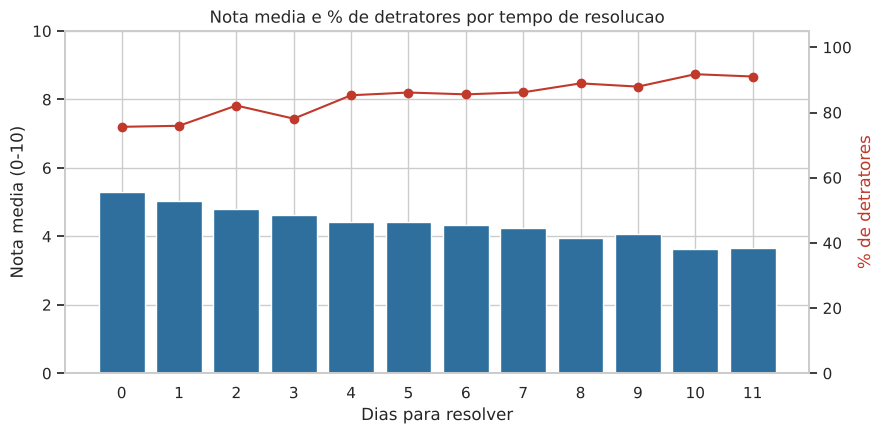

Correlacao entre tempo de resolucao e nota: -0.19


In [7]:
resumo_resolucao = resumo_por_grupo(df, 'resolution_time_days')
display(resumo_resolucao)

grafico_nota_e_detratores(resumo_resolucao, 'Nota media e % de detratores por tempo de resolucao', 'Dias para resolver')

print(f"Correlacao entre tempo de resolucao e nota: {df['resolution_time_days'].corr(df['nps_score']):.2f}")

Conclusao:

O tempo de resolução também afeta a nota, mas com menor intensidade do que o número de reclamações. A média cai gradualmente de 5,3, quando o problema é resolvido no mesmo dia, para 3,7 após 11 dias.

A correlação de -0,19 é fraca e não há um ponto de queda acentuada. Isso indica que a existência do problema tem maior impacto na satisfação do cliente do que o tempo necessário para resolvê-lo.

## 8. Atraso x reclamacoes

**Pergunta:** a combinacao de atraso na entrega e reclamacoes esta associada a resultados piores?

Faixas combinadas com a analise de logistica, para as duas tabelas baterem:

- **Atraso:** 0, 1, 2, 3 e 4+ dias
- **Reclamacoes:** 0-1, 2-3, 4-5 e 6+

Nota media por combinacao:


faixa_reclamacoes,0-1,2-3,4-5,6+
faixa_atraso,,,,
0 dias,8.1,7.1,6.0,4.8
1 dia,8.0,6.5,5.1,4.2
2 dias,7.6,5.5,4.4,3.1
3 dias,6.8,4.3,3.4,2.0
4+ dias,6.9,2.6,1.9,1.3


Numero de pedidos em cada combinacao:


faixa_reclamacoes,0-1,2-3,4-5,6+
faixa_atraso,,,,
0 dias,73,100,69,30
1 dia,31,214,228,134
2 dias,23,186,299,130
3 dias,9,156,238,113
4+ dias,5,116,197,114


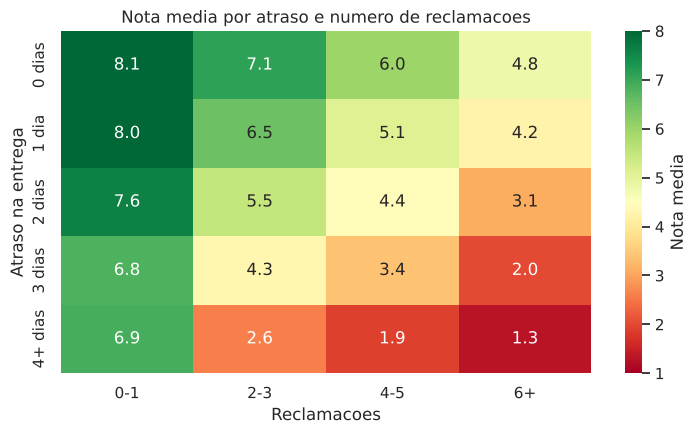

In [8]:
df['faixa_atraso'] = pd.cut(df['delivery_delay_days'], bins=[-1, 0, 1, 2, 3, 100],
                            labels=['0 dias', '1 dia', '2 dias', '3 dias', '4+ dias'])
df['faixa_reclamacoes'] = pd.cut(df['complaints_count'], bins=[-1, 1, 3, 5, 100],
                                 labels=['0-1', '2-3', '4-5', '6+'])

matriz_nota = df.pivot_table(index='faixa_atraso', columns='faixa_reclamacoes',
                             values='nps_score', aggfunc='mean', observed=True).round(1)
matriz_pedidos = df.pivot_table(index='faixa_atraso', columns='faixa_reclamacoes',
                                values='nps_score', aggfunc='size', observed=True)

print('Nota media por combinacao:')
display(matriz_nota)
print('Numero de pedidos em cada combinacao:')
display(matriz_pedidos)

plt.figure(figsize=(7.5, 4.5))
sns.heatmap(matriz_nota, annot=True, fmt='.1f', cmap='RdYlGn', vmin=1, vmax=8,
            cbar_kws={'label': 'Nota media'})
plt.title('Nota media por atraso e numero de reclamacoes')
plt.xlabel('Reclamacoes')
plt.ylabel('Atraso na entrega')
plt.tight_layout()
plt.show()

Conclusao:

Atrasos e reclamações têm efeito combinado sobre a satisfação. Sem atraso e com até uma reclamação, a nota média é 8,1. Já com 4 ou mais dias de atraso e 6 ou mais reclamações, cai para 1,3.

Os dois fatores também afetam a nota de forma independente. Com 2 a 3 reclamações, a média cai de 7,1 sem atraso para 2,6 com atraso de 4 dias ou mais. Com 4 a 5 reclamações, cai de 6,0 para 1,9.

A faixa de 0 a 1 reclamação deve ser interpretada com cautela, pois há poucos pedidos nos níveis mais altos de atraso, o que reduz a confiabilidade da comparação.

## 9. Perfil do cliente

**Pergunta:** existem diferencas na satisfacao por regiao, idade ou valor do pedido?

In [9]:
df['faixa_idade'] = pd.cut(df['customer_age'], bins=[17, 29, 39, 49, 59, 100],
                           labels=['18-29', '30-39', '40-49', '50-59', '60+'])
df['faixa_valor'] = pd.cut(df['order_value'], bins=[0, 200, 400, 600, 1000, 1e9],
                           labels=['Ate 200', '200-400', '400-600', '600-1000', '1000+'])
df['faixa_tempo_cliente'] = pd.cut(df['customer_tenure_months'], bins=[0, 12, 36, 60, 1000],
                                   labels=['Ate 1 ano', '1-3 anos', '3-5 anos', '5+ anos'])

for coluna, titulo in [('customer_region', 'Regiao'), ('faixa_idade', 'Faixa de idade'),
                       ('faixa_valor', 'Valor do pedido'), ('faixa_tempo_cliente', 'Tempo de cliente')]:
    print(f'=== {titulo} ===')
    display(resumo_por_grupo(df, coluna))

=== Regiao ===


,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
customer_region,,,,,
Centro-Oeste,461,4.20,84.60,5.21,-79.0
Nordeste,475,4.44,85.68,4.42,-81.0
Norte,502,4.38,85.26,3.39,-82.0
Sudeste,514,4.39,83.66,4.47,-79.0
Sul,513,4.48,83.43,4.48,-79.0


=== Faixa de idade ===


,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
faixa_idade,,,,,
18-29,558,4.52,83.15,4.12,-79.0
30-39,490,4.24,85.10,4.90,-80.0
40-49,490,4.27,87.35,3.06,-84.0
50-59,472,4.37,83.69,4.87,-79.0
60+,455,4.49,83.30,5.05,-78.0


=== Valor do pedido ===


,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
faixa_valor,,,,,
Ate 200,506,4.18,88.14,2.17,-86.0
200-400,808,4.46,83.54,4.83,-79.0
400-600,574,4.30,85.19,4.70,-80.0
600-1000,441,4.52,81.86,5.67,-76.0
1000+,136,4.53,82.35,4.41,-78.0


=== Tempo de cliente ===


,pedidos,nota_media,pct_detratores,pct_promotores,nps_grupo
faixa_tempo_cliente,,,,,
Ate 1 ano,237,4.15,86.50,3.38,-83.0
1-3 anos,487,4.54,82.96,4.72,-78.0
3-5 anos,471,4.29,86.41,2.97,-83.0
5+ anos,1270,4.39,84.02,4.96,-79.0


,menor_nota,maior_nota,diferenca
Regiao,4.20,4.48,0.3
Faixa de idade,4.24,4.52,0.3
Valor do pedido,4.18,4.53,0.4
Atraso,2.00,6.85,4.8
Reclamacoes,2.83,7.89,5.1


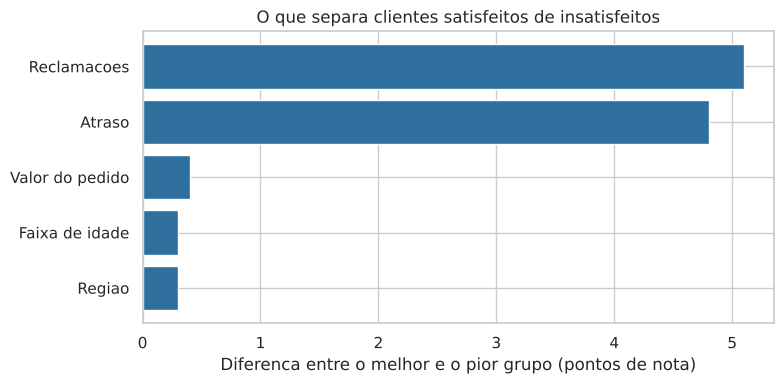

In [10]:
# Comparacao visual: amplitude das notas medias por perfil x por experiencia
comparacao = {
    'Regiao': resumo_por_grupo(df, 'customer_region')['nota_media'],
    'Faixa de idade': resumo_por_grupo(df, 'faixa_idade')['nota_media'],
    'Valor do pedido': resumo_por_grupo(df, 'faixa_valor')['nota_media'],
    'Reclamacoes': resumo_por_grupo(df, 'faixa_reclamacoes')['nota_media'],
    'Atraso': resumo_por_grupo(df, 'faixa_atraso')['nota_media'],
}
amplitude = pd.DataFrame({
    'menor_nota': {k: v.min() for k, v in comparacao.items()},
    'maior_nota': {k: v.max() for k, v in comparacao.items()},
})
amplitude['diferenca'] = (amplitude['maior_nota'] - amplitude['menor_nota']).round(1)
amplitude = amplitude.sort_values('diferenca')
display(amplitude)

plt.figure(figsize=(8, 4))
plt.barh(amplitude.index, amplitude['diferenca'], color=PALETA)
plt.xlabel('Diferenca entre o melhor e o pior grupo (pontos de nota)')
plt.title('O que separa clientes satisfeitos de insatisfeitos')
plt.tight_layout()
plt.show()

Conclusao:

O perfil do cliente tem pouco impacto na nota. As médias ficam entre 4,2 e 4,5 por região, faixa etária e valor do pedido, com diferença máxima de apenas 0,4 ponto entre os grupos.

Em comparação, a variação entre grupos de reclamações ultrapassa 5 pontos, enquanto no atraso chega a 4,8 pontos.

Isso indica que a insatisfação está muito mais relacionada ao que aconteceu com o pedido do que ao perfil do cliente. Portanto, ações focadas apenas em região ou idade tendem a ter pouco efeito; o maior impacto está na melhoria da operação.

## 10. NPS x recompra

**Pergunta:** clientes mais satisfeitos voltam a comprar? Esse resultado ajuda a responder a Etapa 1 do desafio (como o NPS impacta a recompra).

**Atencao:** a recompra acontece **depois** da experiencia e da pesquisa. Ela e consequencia da satisfacao, nao causa. Por isso entra aqui para mostrar o valor do NPS, e nao como fator que explica a nota.

,pedidos,taxa_recompra
categoria_nps,,
Detrator,2083,0.0
Neutro,274,37.2
Promotor,108,100.0


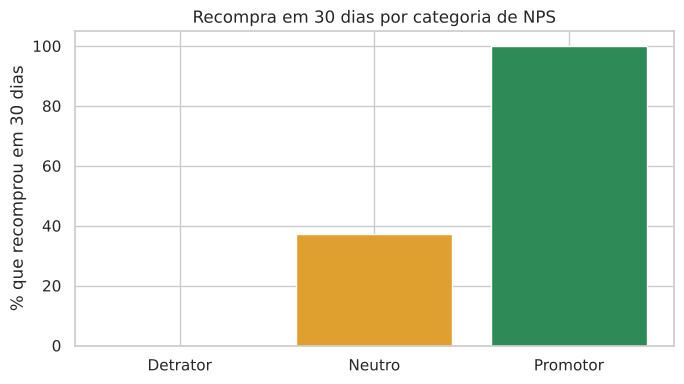

Menor nota entre quem recomprou: 8.0
Clientes que recompraram: 210 de 2465


In [11]:
# Taxa de recompra em 30 dias por categoria de NPS
recompra = df.groupby('categoria_nps').agg(
    pedidos=('repeat_purchase_30d', 'size'),
    taxa_recompra=('repeat_purchase_30d', lambda s: s.mean() * 100),
).reindex(['Detrator', 'Neutro', 'Promotor']).round(1)
display(recompra)

plt.figure(figsize=(7, 4))
plt.bar(recompra.index, recompra['taxa_recompra'], color=['#C0392B', '#E0A030', '#2E8B57'])
plt.ylabel('% que recomprou em 30 dias')
plt.ylim(0, 105)
plt.title('Recompra em 30 dias por categoria de NPS')
plt.tight_layout()
plt.show()

# Checagem: qual a menor nota entre quem recomprou?
menor_nota_recompra = df.loc[df['repeat_purchase_30d'] == 1, 'nps_score'].min()
print(f'Menor nota entre quem recomprou: {menor_nota_recompra}')
print(f'Clientes que recompraram: {df["repeat_purchase_30d"].sum()} de {len(df)}')

Conclusao:

A recompra está fortemente associada ao NPS. Nenhum detrator recomprou em 30 dias, 37% dos neutros recompraram e 100% dos promotores voltaram a comprar. Entre os clientes que recompraram, a menor nota foi 8.

Para o negócio, isso mostra que transformar clientes em detratores representa risco direto de perda de receita futura. Melhorar o NPS também ajuda a preservar a recompra.

Para o modelo preditivo, essa variável deve ficar fora. Como a recompra acontece depois da pesquisa, utilizá-la para prever o NPS causaria vazamento de informação, usando um evento futuro para explicar uma nota passada.

## 11. Resumo dos achados

| Achado | Evidencia |
| --- | --- |
| Reclamacao e o fator mais forte da minha parte | Nota cai de 8,5 (zero reclamacoes) para cerca de 2 (8 ou mais). Correlacao -0,49 |
| Contato com atendimento e sintoma de problema | Nota 5,5 sem contato, 2,6 com quatro contatos. Correlacao -0,35 |
| Demora para resolver pesa, mas menos | Nota 5,3 no mesmo dia, 3,7 com 11 dias. Correlacao -0,19 |
| Atraso e reclamacao se somam | 8,1 no melhor cenario, 1,3 no pior |
| Atraso e reclamacao pesam de forma independente | Com 2-3 reclamacoes, nota 7,1 sem atraso e 2,6 com 4+ dias; sem atraso, nota 4,8 com 6+ reclamacoes |
| Detrator nao volta a comprar | Recompra em 30 dias: 0% dos detratores, 37% dos neutros, 100% dos promotores |
| Perfil do cliente quase nao importa | Diferenca de ate 0,4 ponto entre grupos de regiao, idade e valor |

**Recomendacoes sustentadas pelos dados**

1. Reduzir a quantidade de reclamacoes por pedido, atacando a causa que as gera. E o fator mais forte da minha parte.
2. Resolver no primeiro contato. Dar autonomia ao atendente para evitar o segundo e o terceiro contato.
3. Agir de forma proativa quando houver atraso e reclamacao no mesmo pedido, que e a combinacao com as piores notas.
4. Nao segmentar acao por regiao, idade ou ticket, porque esses cortes nao explicam a nota.

**Limitacoes**

- **Correlacao nao prova causa.** Os dados mostram que reclamacao e nota baixa andam juntas, mas nao provam a direcao. Para provar, seria preciso testar uma mudanca e medir o resultado.
- **Casos que merecem validacao** (secao 3), como reclamacao registrada sem contato com o atendimento.
- **Faltam informacoes importantes:** motivo da reclamacao, categoria do produto e canal de compra. Sem isso nao da para dizer *por que* o cliente reclamou.
- **Grupos pequenos** em contatos acima de 5 e reclamacoes acima de 8, onde as medias sao instaveis.
- **Recompra nao pode entrar no modelo:** ela acontece depois da pesquisa e separa as categorias de forma perfeita (vazamento de informacao).
- **Poucos promotores** (4% da base), o que limita o que se pode dizer sobre o que encanta o cliente.